## Step 7A: Build the Budget Engines and Test with Base Settings

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
from metrics import summarize
from budget_engine import (BUDGET, MIN_SHARE, MAX_SHARE, BASE_B,
                           roas_proportional, diminishing_returns)

# Historical ROAS per platform from the raw data (read-only)
df = pd.read_csv("../data/raw/ads_10k.csv", parse_dates=["date"])
roas = summarize(df, "platform")["roas"].sort_values(ascending=False)

engine_a = roas_proportional(roas, BUDGET, MIN_SHARE, MAX_SHARE)
engine_c = diminishing_returns(roas, BUDGET, MIN_SHARE, MAX_SHARE, BASE_B)

table = pd.DataFrame({
    "ROAS": roas,
    "Engine A share (%)": engine_a / BUDGET * 100,
    "Engine A (Rs.)": engine_a,
    "Engine C share (%)": engine_c / BUDGET * 100,
    "Engine C (Rs.)": engine_c,
})

print(f"Budget recommendation for Rs. {BUDGET:,} "
      f"(limits: {MIN_SHARE:.0%} to {MAX_SHARE:.0%} per platform, b = {BASE_B})\n")
print(table.to_string(float_format=lambda x: f"{x:,.2f}"))

print("\nValidation checks")
for name, plan in [("Engine A", engine_a), ("Engine C", engine_c)]:
    total_ok = abs(plan.sum() - BUDGET) < 1
    limits_ok = ((plan >= BUDGET * MIN_SHARE - 1) & (plan <= BUDGET * MAX_SHARE + 1)).all()
    print(f"  {name}: total equals budget {'PASS' if total_ok else 'FAIL'}, "
          f"within limits {'PASS' if limits_ok else 'FAIL'}")

Budget recommendation for Rs. 1,000,000 (limits: 5% to 40% per platform, b = 0.7)

           ROAS  Engine A share (%)  Engine A (Rs.)  Engine C share (%)  Engine C (Rs.)
platform                                                                               
Google     4.52               27.33      273,276.90               40.00      400,000.00
Instagram  3.94               23.82      238,210.40               26.71      267,089.61
Facebook   3.67               22.19      221,886.34               21.08      210,809.32
TikTok     2.66               16.08      160,822.25                7.21       72,101.07
YouTube    1.75               10.58      105,804.11                5.00       50,000.00

Validation checks
  Engine A: total equals budget PASS, within limits PASS
  Engine C: total equals budget PASS, within limits PASS


## Step 7B: Sensitivity Check and Strategy Comparison

In [2]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
from metrics import summarize
from budget_engine import (BUDGET, MIN_SHARE, MAX_SHARE, BASE_B,
                           roas_proportional, diminishing_returns, expected_revenue)

# Historical metrics per platform from the raw data (read-only)
df = pd.read_csv("../data/raw/ads_10k.csv", parse_dates=["date"])
platform = summarize(df, "platform")
roas = platform["roas"].sort_values(ascending=False)

engine_a = roas_proportional(roas, BUDGET, MIN_SHARE, MAX_SHARE)
engine_c = diminishing_returns(roas, BUDGET, MIN_SHARE, MAX_SHARE, BASE_B)

# ---------- Final recommendation table ----------
recommendation = pd.DataFrame({
    "ROAS": roas,
    "Engine A share (%)": engine_a / BUDGET * 100,
    "Engine A (Rs.)": engine_a,
    "Engine C share (%)": engine_c / BUDGET * 100,
    "Engine C (Rs.)": engine_c,
})
recommendation.to_csv("../outputs/tables/budget_recommendation.csv")

# ---------- Part 1: sensitivity of Engine C to b ----------
B_VALUES = [0.6, 0.7, 0.8]
sensitivity = pd.DataFrame({
    f"b = {b}": diminishing_returns(roas, BUDGET, MIN_SHARE, MAX_SHARE, b) / BUDGET * 100
    for b in B_VALUES
})
sensitivity.to_csv("../outputs/tables/budget_sensitivity.csv")

print("Engine C budget share (%) for different b values\n")
print(sensitivity.to_string(float_format=lambda x: f"{x:,.1f}"))

# ---------- Part 2: strategy comparison ----------
spend_share = platform["spend"].reindex(roas.index) / platform["spend"].sum()
strategies = {
    "Equal split": pd.Series(BUDGET / len(roas), index=roas.index),
    "Historical spend": BUDGET * spend_share,
    "Engine A (ROAS)": engine_a,
    "Engine C (diminishing)": engine_c,
}

revenue_columns = {b: f"Revenue b={b} (Rs.)" for b in B_VALUES}
comparison = pd.DataFrame({
    name: {revenue_columns[b]: expected_revenue(plan, roas, BUDGET, b).sum()
           for b in B_VALUES}
    for name, plan in strategies.items()
}).T

base_column = revenue_columns[BASE_B]
comparison["Uplift vs equal (%)"] = (
    comparison[base_column] / comparison.loc["Equal split", base_column] - 1) * 100
comparison.to_csv("../outputs/tables/strategy_comparison.csv")

print(f"\nExpected revenue of each strategy for a budget of Rs. {BUDGET:,}")
print("(uplift is measured at b = 0.7)\n")
print(comparison.to_string(float_format=lambda x: f"{x:,.2f}"))

# ---------- Validation checks ----------
equal_revenue = comparison.loc["Equal split", list(revenue_columns.values())]
print("\nValidation checks")
print("  Each sensitivity split sums to 100%:",
      "PASS" if (abs(sensitivity.sum() - 100) < 1e-6).all() else "FAIL")
print("  Equal split revenue is the same for every b:",
      "PASS" if np.allclose(equal_revenue, equal_revenue.iloc[0]) else "FAIL")
print("\nSaved: budget_recommendation.csv, budget_sensitivity.csv, strategy_comparison.csv")

Engine C budget share (%) for different b values

           b = 0.6  b = 0.7  b = 0.8
platform                            
Google        37.0     40.0     40.0
Instagram     26.2     26.7     29.4
Facebook      22.0     21.1     20.6
TikTok         9.8      7.2      5.0
YouTube        5.0      5.0      5.0

Expected revenue of each strategy for a budget of Rs. 1,000,000
(uplift is measured at b = 0.7)

                        Revenue b=0.6 (Rs.)  Revenue b=0.7 (Rs.)  Revenue b=0.8 (Rs.)  Uplift vs equal (%)
Equal split                    3,308,000.00         3,308,000.00         3,308,000.00                 0.00
Historical spend               3,450,803.83         3,543,495.99         3,657,554.26                 7.12
Engine A (ROAS)                3,452,191.67         3,485,550.40         3,521,488.75                 5.37
Engine C (diminishing)         3,505,898.72         3,588,053.75         3,683,362.26                 8.47

Validation checks
  Each sensitivity split sums to 100%: 

## Step 7C: Create Recommendation and Strategy Charts

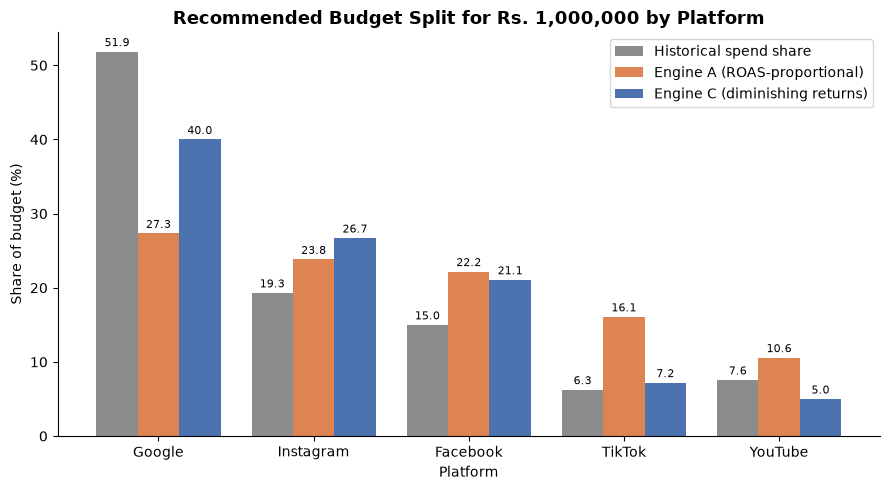

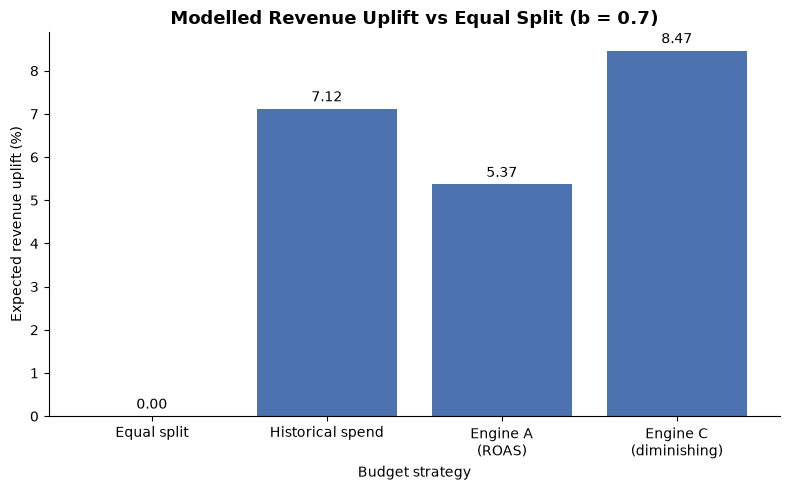

Saved 2 charts to outputs/figures/


In [3]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd
from metrics import summarize

FIG_DIR = "../outputs/figures/"

# Load the saved result tables and the raw data (read-only)
recommendation = pd.read_csv("../outputs/tables/budget_recommendation.csv", index_col="platform")
comparison = pd.read_csv("../outputs/tables/strategy_comparison.csv", index_col=0)
df = pd.read_csv("../data/raw/ads_10k.csv", parse_dates=["date"])
historical_spend = summarize(df, "platform")["spend"]

# ---------- Chart 1: budget split by platform ----------
shares = pd.DataFrame({
    "Historical spend share": historical_spend / historical_spend.sum() * 100,
    "Engine A (ROAS-proportional)": recommendation["Engine A share (%)"],
    "Engine C (diminishing returns)": recommendation["Engine C share (%)"],
}).reindex(recommendation.index)

fig, ax = plt.subplots(figsize=(9, 5))
shares.plot(kind="bar", ax=ax, color=["#8C8C8C", "#DD8452", "#4C72B0"], rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
ax.set_title("Recommended Budget Split for Rs. 1,000,000 by Platform",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Platform")
ax.set_ylabel("Share of budget (%)")
ax.legend(title=None)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR + "06_budget_split.png", dpi=200)
plt.show()

# ---------- Chart 2: modelled uplift versus the equal split ----------
uplift = comparison["Uplift vs equal (%)"]
labels = [name.replace(" (", "\n(") for name in uplift.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, uplift.values, color="#4C72B0")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_title("Modelled Revenue Uplift vs Equal Split (b = 0.7)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Budget strategy")
ax.set_ylabel("Expected revenue uplift (%)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR + "07_strategy_uplift.png", dpi=200)
plt.show()

print("Saved 2 charts to outputs/figures/")